# Progress 1 – Bukti Capaian Rubrik (14 Item)

**Proyek Akhir Data Science** · Analisis Pengaruh Kegiatan Internal dan Eksternal terhadap Performa Akademik Mahasiswa
UPN "Veteran" Yogyakarta · Dosen pengampu: Dhimas Arief Dharmawan, S.T., Ph.D.

Anggota kelompok: Aji Gersome Diliadi (123240043) · Muhammad Restu Firmansyah (123240050) · Yusyfi Akira Arlyn Alzena (123240061) · Hendri Prasetyo (123240066)

## Peta capaian rubrik

| No | Aspek | Item penilaian | Bagian di notebook ini | Rujukan di notebook utama |
|---|---|---|---|---|
| 1 | Data Understanding | Sumber data & lisensi/izin | Bagian 1 | Bagian 2 |
| 2 | Data Understanding | Data dictionary | Bagian 2 | Bagian 2 |
| 3 | Data Understanding | Kualitas data | Bagian 3 | 3.1–3.4 |
| 4 | Data Understanding | EDA berinsight | Bagian 4 | Bagian 3 dan 5 |
| 5 | Data Understanding | Representativitas & bias sampel | Bagian 5 | 5.5 |
| 6 | EDA | Statistik deskriptif | Bagian 6 | 3.3, 5.1 |
| 7 | EDA | Visualisasi fitur dan target | Bagian 7 | 3.4, 5.1–5.3 |
| 8 | EDA | Korelasi dan minimal 3 insight | Bagian 8 | 5.4 |
| 9 | Audit kualitas data | Missing, outlier, duplikat tiap kolom | Bagian 9 | 3.5 |
| 10 | Cleaning | Strategi penyelesaian masalah | Bagian 10 | Bagian 4 |
| 11 | Cleaning | Sebelum vs sesudah | Bagian 11 | Bagian 4 |
| 12 | Preprocessing | Encoding, scaling, imbalance + alasan | Bagian 12 | 6, 6.1 |
| 13 | Preprocessing | Split train/test | Bagian 13 | Bagian 6 |
| 14 | Feature Selection | Pemilihan fitur + alasan + bukti | Bagian 14 | Bagian 7 |

In [1]:
import os, warnings
os.environ.setdefault('MPLCONFIGDIR', '/tmp/mplconfig')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from IPython.display import display

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
BIRU, ORANYE = '#2F5D8A', '#D9822B'

RAW, CLEAN = 'data/Students_Performance_data_set.csv', 'data/data_bersih.csv'
for f in (RAW, CLEAN):
    assert os.path.exists(f), f'File {f} tidak ditemukan. Jalankan notebook dari folder utama repository.'

NAMA = ['admit_year','gender','age','hsc_year','program','semester','scholarship','uni_transport','study_hours',
        'study_sessions','learning_mode','smartphone','pc','social_media_hours','english','attendance','probation',
        'suspension','consultancy','skills','skill_hours','interest','relationship','cocurricular','living_with',
        'health_issue','prev_sgpa','disability','cgpa','credits','income']          # sama dengan notebook utama
mentah = pd.read_csv(RAW); mentah.columns = NAMA
mentah['att'] = pd.to_numeric(mentah.attendance, errors='coerce')                   # hanya untuk pemeriksaan
bersih = pd.read_csv(CLEAN)                                                         # hasil cleaning notebook utama
print('Data mentah :', mentah.shape, '| Data bersih:', bersih.shape)

Data mentah : (1194, 32) | Data bersih: (1155, 34)


---
# 1. Sumber data dan lisensi

| | |
|---|---|
| **Dataset** | *Students_Academic_Performance_Evaluation_Dataset* (Versi 1), file asli `Students_Performance_data_set.xlsx` |
| **Penulis** | Rahman, A. T., Lamia, S., Shishir, A. H., & Barsa, M. M. (2024) |
| **Repositori** | Mendeley Data, https://doi.org/10.17632/dc3797vf3t.1 |
| **Lisensi/izin** | **CC BY 4.0**: boleh dipakai dan diolah dengan menyebut sumber |
| **Isi** | Survei online mahasiswa *Computer Science and Engineering* di universitas swasta di Bangladesh; satu baris = satu mahasiswa |
| **Salinan di repo** | `data/Students_Performance_data_set.csv` (konversi CSV; XLSX tidak disertakan) |

In [2]:
print(f'Jumlah responden: {len(mentah)} | jumlah variabel: {mentah.shape[1] - 1}')   # -1 karena kolom att buatan

Jumlah responden: 1194 | jumlah variabel: 31


# 2. Data dictionary

Seluruh 31 variabel. Tipe analitis adalah makna variabel; tipe penyimpanan aktual diambil langsung dari data. Mata uang `income` dan batas resmi skala SGPA/CGPA tidak dijelaskan di sumber, sehingga **tidak diasumsikan**.

In [3]:
kamus = pd.DataFrame([
 ('admit_year','Tahun masuk universitas','Numerik diskret','tahun kalender'),
 ('gender','Gender responden','Kategorikal nominal','kategori'),
 ('age','Usia','Numerik diskret','tahun'),
 ('hsc_year','Tahun lulus HSC (sekolah menengah)','Numerik diskret','tahun kalender'),
 ('program','Program studi','Kategorikal nominal','kategori'),
 ('semester','Semester saat survei','Numerik diskret','semester'),
 ('scholarship','Memiliki beasiswa prestasi','Kategorikal biner','Yes/No'),
 ('uni_transport','Memakai transportasi universitas','Kategorikal biner','Yes/No'),
 ('study_hours','Durasi belajar harian','Numerik','jam/hari'),
 ('study_sessions','Frekuensi belajar harian','Numerik diskret','sesi/hari'),
 ('learning_mode','Preferensi cara belajar','Kategorikal nominal','kategori'),
 ('smartphone','Menggunakan smartphone','Kategorikal biner','Yes/No'),
 ('pc','Memiliki komputer pribadi','Kategorikal biner','Yes/No'),
 ('social_media_hours','Durasi media sosial','Numerik','jam/hari'),
 ('english','Kemampuan bahasa Inggris','Kategorikal ordinal','Basic/Intermediate/Advance'),
 ('attendance','Rata-rata kehadiran kelas','Numerik konseptual (teks di CSV mentah)','persen (%)'),
 ('probation','Pernah probation akademik','Kategorikal biner','Yes/No'),
 ('suspension','Pernah diskors','Kategorikal biner','Yes/No'),
 ('consultancy','Konsultasi akademik dengan dosen','Kategorikal biner','Yes/No'),
 ('skills','Keterampilan yang dilaporkan','Kategorikal nominal','teks'),
 ('skill_hours','Durasi pengembangan keterampilan','Numerik','jam/hari'),
 ('interest','Bidang minat','Kategorikal nominal','teks'),
 ('relationship','Status hubungan','Kategorikal nominal','kategori'),
 ('cocurricular','Mengikuti kegiatan ko-kurikuler','Kategorikal biner','Yes/No'),
 ('living_with','Kondisi tempat tinggal','Kategorikal nominal','kategori'),
 ('health_issue','Memiliki masalah kesehatan','Kategorikal biner (label perlu diseragamkan)','Yes/No'),
 ('prev_sgpa','SGPA semester sebelumnya','Numerik kontinu','poin SGPA'),
 ('disability','Memiliki disabilitas fisik','Kategorikal biner','Yes/No'),
 ('cgpa','CGPA saat survei (TARGET)','Numerik kontinu','poin CGPA'),
 ('credits','Kredit yang telah diselesaikan','Numerik','kredit'),
 ('income','Pendapatan keluarga per bulan','Numerik','unit mata uang/bulan (mata uang belum terverifikasi)'),
], columns=['variabel','makna','tipe_analitis','satuan_kode']).set_index('variabel')

assert list(kamus.index) == NAMA, 'Kamus tidak mencakup seluruh variabel'
kamus['tipe_di_data'] = mentah[NAMA].dtypes.astype(str)
kamus['jml_unik'] = mentah[NAMA].nunique()
display(kamus)
print('Variabel di kamus:', len(kamus), '| variabel di data mentah:', len(NAMA))

,makna,tipe_analitis,satuan_kode,tipe_di_data,jml_unik
variabel,,,,,
admit_year,Tahun masuk universitas,Numerik diskret,tahun kalender,int64,11
gender,Gender responden,Kategorikal nominal,kategori,str,2
age,Usia,Numerik diskret,tahun,int64,10
hsc_year,Tahun lulus HSC (sekolah menengah),Numerik diskret,tahun kalender,int64,12
program,Program studi,Kategorikal nominal,kategori,str,1
semester,Semester saat survei,Numerik diskret,semester,int64,22
scholarship,Memiliki beasiswa prestasi,Kategorikal biner,Yes/No,str,2
uni_transport,Memakai transportasi universitas,Kategorikal biner,Yes/No,str,2
study_hours,Durasi belajar harian,Numerik,jam/hari,int64,12


Variabel di kamus: 31 | variabel di data mentah: 31


# 3. Kualitas data (data mentah)

Pemeriksaan pada data mentah: nilai kosong, duplikat, tipe data, label tidak seragam, nilai tidak wajar, dan outlier.

In [4]:
def iqr_outlier(s):
    s = pd.to_numeric(s, errors='coerce').dropna()
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum())

nol = mentah[mentah.cgpa == 0]
masalah = pd.DataFrame([
 ('Nilai kosong',               f"{int(mentah[NAMA].isna().sum().sum())} sel (kolom skills)", 'Diisi label Unknown'),
 ('Baris duplikat utuh',        int(mentah[NAMA].duplicated().sum()), 'Tidak ada tindakan'),
 ('Kehadiran bukan angka',      str(mentah.attendance[mentah.att.isna()].tolist()), 'Dijadikan kosong (tidak ditebak)'),
 ('Label health_issue ganda',   int((~mentah.health_issue.isin(['Yes','No'])).sum()), "'no' dan 'N' disatukan menjadi 'No'"),
 ("Label relationship ganda",   int((mentah.relationship == 'In a relationship').sum()), "Disatukan ke 'Relationship'"),
 ('Label skills tak seragam',   int(mentah.skills.str.strip().str.lower().isin(['nothing','no skills','no skill']).sum()), "Disatukan ke 'no skill'"),
 ('CGPA = 0 (mahasiswa baru)',  f"{len(nol)} baris; semester 1: {int((nol.semester==1).sum())}; kredit 0: {int((nol.credits==0).sum())}", 'Dikeluarkan dari analisis'),
 ('Tahun HSC > 2024',           int((mentah.hsc_year > 2024).sum()), 'Dijadikan kosong'),
 ('Semester > 14',              int((mentah.semester > 14).sum()), 'Dipertahankan, ditandai (lihat Bagian 10)'),
], columns=['masalah', 'temuan', 'penanganan'])
display(masalah)
print('Outlier IQR (data mentah):',
      {k: iqr_outlier(mentah[k]) for k in ['cgpa','att','study_hours','social_media_hours','skill_hours','income']})

,masalah,temuan,penanganan
0,Nilai kosong,1 sel (kolom skills),Diisi label Unknown
1,Baris duplikat utuh,0,Tidak ada tindakan
2,Kehadiran bukan angka,['94-98'],Dijadikan kosong (tidak ditebak)
3,Label health_issue ganda,4,'no' dan 'N' disatukan menjadi 'No'
4,Label relationship ganda,1,Disatukan ke 'Relationship'
5,Label skills tak seragam,12,Disatukan ke 'no skill'
6,CGPA = 0 (mahasiswa baru),39 baris; semester 1: 37; kredit 0: 35,Dikeluarkan dari analisis
7,Tahun HSC > 2024,1,Dijadikan kosong
8,Semester > 14,15,"Dipertahankan, ditandai (lihat Bagian 10)"


Outlier IQR (data mentah): {'cgpa': 45, 'att': 36, 'study_hours': 22, 'social_media_hours': 71, 'skill_hours': 8, 'income': 61}


**Kesimpulan.** Dataset hampir lengkap (hanya 1 sel kosong) dan tanpa baris ganda. Masalah utamanya ada pada **konsistensi**, bukan kelengkapan: label ganda, satu isian kehadiran berbentuk rentang (`94-98`), satu tahun HSC mustahil (2028), dan **39 mahasiswa ber-CGPA 0** (37 di semester 1, 35 belum punya kredit) yang bukan nilai sebenarnya melainkan belum punya nilai. Outlier lain (jam media sosial, pendapatan) masih masuk akal sehingga tidak dibuang otomatis.

# 4. EDA berinsight

Dua pertanyaan utama: seperti apa sebaran CGPA, dan siapa yang cenderung ber-CGPA rendah?

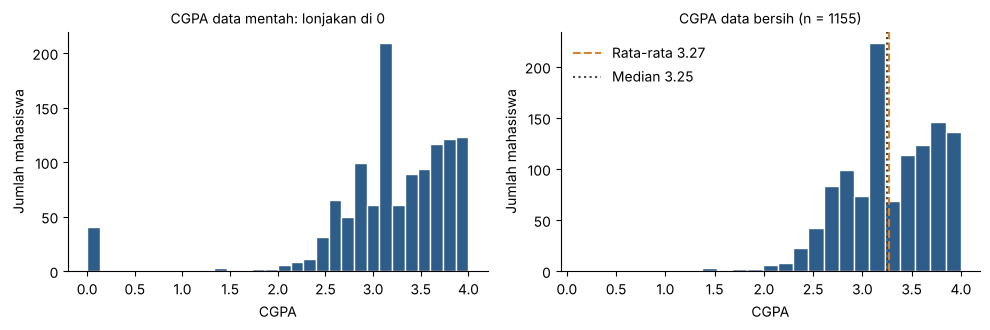

Rata-rata CGPA menurut probation:
           mean  count
probation             
No         3.37    858
Yes        3.00    297

Skewness CGPA: -0.84


In [5]:
d = bersih
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].hist(mentah.cgpa, bins=30, color=BIRU, edgecolor='white')
axs[0].set_title('CGPA data mentah: lonjakan di 0', fontsize=10)
axs[1].hist(d.cgpa, bins=25, color=BIRU, edgecolor='white')
axs[1].axvline(d.cgpa.mean(), color=ORANYE, ls='--', label=f'Rata-rata {d.cgpa.mean():.2f}')
axs[1].axvline(d.cgpa.median(), color='#444', ls=':', label=f'Median {d.cgpa.median():.2f}')
axs[1].set_title('CGPA data bersih (n = %d)' % len(d), fontsize=10); axs[1].legend(frameon=False)
for a in axs: a.set_xlabel('CGPA'); a.set_ylabel('Jumlah mahasiswa')
plt.tight_layout(); plt.show()

print('Rata-rata CGPA menurut probation:'); print(d.groupby('probation').cgpa.agg(['mean', 'count']).round(2))
print('\nSkewness CGPA:', round(d.cgpa.skew(), 2))

**Insight EDA.**
1. Lonjakan CGPA = 0 pada data mentah adalah artefak mahasiswa baru, bukan performa; setelah dikeluarkan, distribusi CGPA berbentuk wajar.
2. Distribusi CGPA condong ke kiri (skewness −0,84): mayoritas mahasiswa di atas 3,0 dengan ekor kecil ke nilai rendah, sehingga median (3,25) dipakai berdampingan dengan rata-rata (3,27).
3. Mahasiswa yang pernah *probation* rata-rata ber-CGPA 3,00 dibanding 3,37 yang tidak pernah. Probation kemungkinan juga akibat nilai rendah, jadi ini hubungan, bukan sebab.

# 5. Representativitas dan bias sampel

In [6]:
print('Komposisi gender:'); print(d.gender.value_counts(normalize=True).round(3).to_string())
print('\nAngkatan 2019-2022: %d%%' % round(d.admit_year.between(2019, 2022).mean()*100),
      '| angkatan <2018 atau 2023:', int(((d.admit_year < 2018) | (d.admit_year == 2023)).sum()), 'mahasiswa')
print('Program studi:', d.program.unique().tolist())
print('Menjawab kehadiran 100%% (mentah): %d responden (%d%%)' % ((mentah.att == 100).sum(), round((mentah.att == 100).mean()*100)))
print('Menjawab kehadiran 100%% (bersih): %d responden (%d%%)' % ((d.att == 100).sum(), round((d.att == 100).mean()*100)))

Komposisi gender:
gender
Male      0.566
Female    0.434

Angkatan 2019-2022: 93% | angkatan <2018 atau 2023: 31 mahasiswa
Program studi: ['BCSE']
Menjawab kehadiran 100% (mentah): 357 responden (30%)
Menjawab kehadiran 100% (bersih): 338 responden (29%)


**Potensi bias dan batasan generalisasi.**
- **Cakupan sempit:** semua responden dari satu program (BCSE) di satu universitas swasta, sehingga hasil tidak boleh digeneralisasi ke semua mahasiswa atau prodi lain.
- **Bias pemilihan sampel:** survei online sukarela; mahasiswa yang bersedia mengisi bisa berbeda dari yang tidak.
- **Bias pelaporan (self-report):** sekitar 30% menjawab kehadiran 100%, indikasi pelaporan yang cenderung terlalu positif.
- **Komposisi tidak seimbang:** laki-laki sekitar 57% dan 93% responden berasal dari angkatan 2019–2022.
- **Populasi analisis berubah setelah cleaning:** 39 mahasiswa baru dikeluarkan, sehingga kesimpulan hanya berlaku untuk mahasiswa yang sudah punya CGPA.

Dataset layak untuk mencari **pola awal**, bukan untuk membuktikan sebab-akibat.

# 6. Statistik deskriptif

In [7]:
num_cols = ['age','semester','study_hours','study_sessions','social_media_hours','skill_hours','att','prev_sgpa','cgpa','credits','income']
desk = d[num_cols].describe().T[['count','mean','50%','std','min','max']].rename(columns={'50%': 'median'}).round(2)
desk['skewness'] = d[num_cols].skew().round(2)
display(desk)

,count,mean,median,std,min,max,skewness
age,1155.0,21.39,21.00,1.61,18.00,27.0,0.79
semester,1155.0,6.72,7.00,3.74,1.00,24.0,0.36
study_hours,1155.0,3.13,3.00,1.64,0.00,13.0,1.02
study_sessions,1155.0,1.95,2.00,0.86,0.00,7.0,1.02
social_media_hours,1155.0,3.30,3.00,2.30,0.00,20.0,2.01
skill_hours,1155.0,2.21,2.00,1.30,0.00,12.0,1.58
att,1154.0,88.00,90.00,15.45,0.00,100.0,-2.08
prev_sgpa,1155.0,2.77,2.68,0.74,0.00,4.0,-0.27
cgpa,1155.0,3.27,3.25,0.48,0.13,4.0,-0.84
credits,1155.0,74.23,84.00,47.05,0.00,145.0,-0.06


**Kesimpulan.**
- **CGPA** rata-rata 3,27 (median 3,25, SD 0,48), skewness −0,84: condong ke kiri. Target mendekati normal dengan ekor rendah kecil.
- **Kehadiran** rata-rata 88% dan median 90%, sangat condong ke kiri (menumpuk di 90–100%): variasinya kecil di bagian atas.
- **Jam media sosial, jam belajar, dan jam keterampilan** condong ke kanan (skewness 1,0–2,0): median 2–3 jam/hari, dengan sedikit mahasiswa yang sangat tinggi (maksimum 20, 13, dan 12 jam).
- **SGPA sebelumnya** (rata-rata 2,77) lebih rendah dari CGPA (3,27) dan relatif simetris.
- Nilai ekstrem pada `income`, jam media sosial, dan semester tampak jelas dari selisih median dan maksimum; ini dibahas di Bagian 9.

# 7. Visualisasi fitur dan target

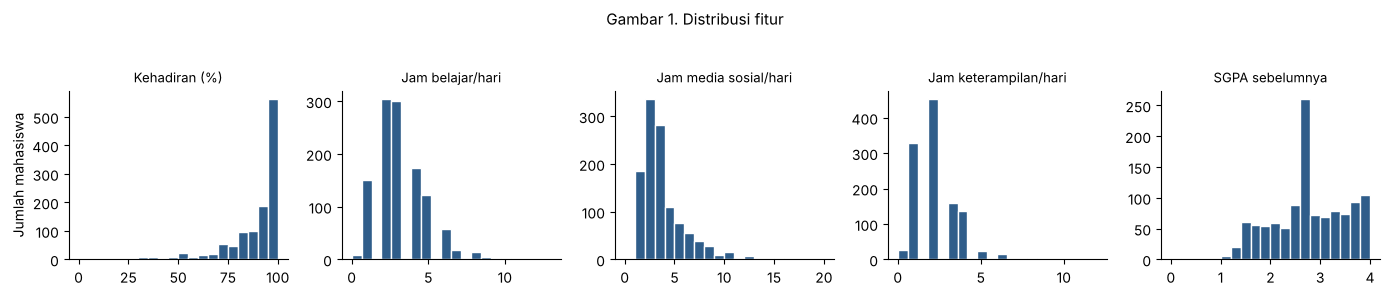

In [8]:
# Gambar 1: distribusi fitur
fitur_v = [('att','Kehadiran (%)'),('study_hours','Jam belajar/hari'),('social_media_hours','Jam media sosial/hari'),
           ('skill_hours','Jam keterampilan/hari'),('prev_sgpa','SGPA sebelumnya')]
fig, axs = plt.subplots(1, 5, figsize=(14, 2.8))
for ax, (k, t) in zip(axs, fitur_v):
    ax.hist(d[k].dropna(), bins=20, color=BIRU, edgecolor='white'); ax.set_title(t, fontsize=9.5)
axs[0].set_ylabel('Jumlah mahasiswa'); plt.suptitle('Gambar 1. Distribusi fitur', y=1.04, fontsize=11)
plt.tight_layout(); plt.show()

**Gambar 1.** Kehadiran menumpuk di 90–100% (condong kiri), sedangkan jam belajar, media sosial, dan keterampilan condong ke kanan dengan beberapa nilai ekstrem (misalnya media sosial sampai 20 jam). SGPA sebelumnya tersebar lebih merata. Karena sebaran tidak normal, hubungan dengan CGPA diuji dengan **Spearman** dan **Mann-Whitney**.

CGPA kehadiran 100%: 3.39 | kehadiran <= 75%: 3.12
CGPA media sosial > 6 jam: 3.16 | 0-2 jam: 3.31


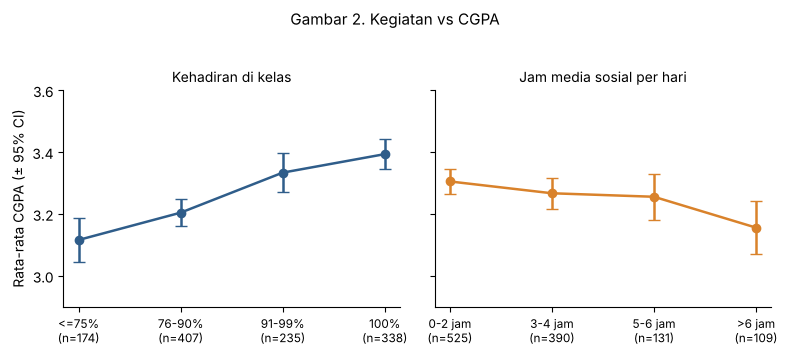

cocurricular: Ya 3.275 (n=485) vs Tidak 3.271 (n=670) | Mann-Whitney p = 0.75


consultancy: Ya 3.256 (n=632) vs Tidak 3.293 (n=523) | Mann-Whitney p = 0.22


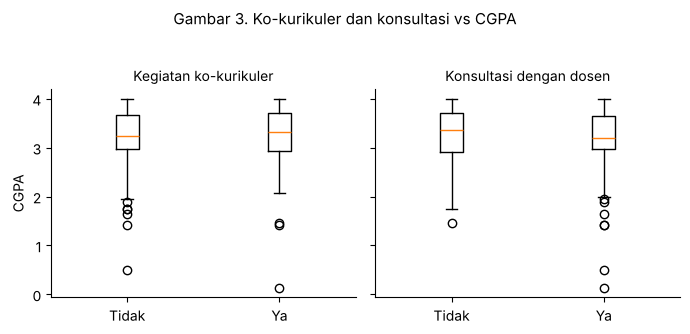

In [9]:
# Gambar 2: fitur vs target (rata-rata CGPA per kelompok, ±95% CI)
def ci(s): return 1.96 * s.std(ddof=1) / np.sqrt(len(s))
dv = d.assign(
    attbin=pd.cut(d.att, [-1, 75, 90, 99, 100], labels=['<=75%','76-90%','91-99%','100%']),
    smbin=pd.cut(d.social_media_hours, [-1, 2, 4, 6, 100], labels=['0-2 jam','3-4 jam','5-6 jam','>6 jam']))
fig, axs = plt.subplots(1, 2, figsize=(8, 3.4), sharey=True)
for ax, col, t, clr in [(axs[0],'attbin','Kehadiran di kelas',BIRU), (axs[1],'smbin','Jam media sosial per hari',ORANYE)]:
    g = dv.groupby(col, observed=True).cgpa
    ax.errorbar(range(len(g.mean())), g.mean(), yerr=g.apply(ci), fmt='o-', color=clr, capsize=4, lw=1.8)
    ax.set_xticks(range(len(g.mean()))); ax.set_xticklabels([f'{k}\n(n={n})' for k, n in g.size().items()], fontsize=8.5)
    ax.set_title(t, fontsize=10); ax.set_ylim(2.9, 3.6)
axs[0].set_ylabel('Rata-rata CGPA (± 95% CI)'); plt.suptitle('Gambar 2. Kegiatan vs CGPA', y=1.03, fontsize=11)
print(f"CGPA kehadiran 100%: {d[d.att == 100].cgpa.mean():.2f} | kehadiran <= 75%: {d[d.att <= 75].cgpa.mean():.2f}")
print(f"CGPA media sosial > 6 jam: {d[d.social_media_hours > 6].cgpa.mean():.2f} | 0-2 jam: {d[d.social_media_hours <= 2].cgpa.mean():.2f}")
plt.tight_layout(); plt.show()

# Gambar 3: kegiatan biner vs target
fig, axs = plt.subplots(1, 2, figsize=(7, 3.2), sharey=True)
for ax, col, t in [(axs[0],'cocurricular','Kegiatan ko-kurikuler'), (axs[1],'consultancy','Konsultasi dengan dosen')]:
    ax.boxplot([d[d[col]=='No'].cgpa, d[d[col]=='Yes'].cgpa], tick_labels=['Tidak','Ya']); ax.set_title(t, fontsize=10)
    ya, tdk = d[d[col]=='Yes'].cgpa, d[d[col]=='No'].cgpa
    print(f"{col}: Ya {ya.mean():.3f} (n={len(ya)}) vs Tidak {tdk.mean():.3f} (n={len(tdk)}) | Mann-Whitney p = {stats.mannwhitneyu(ya, tdk).pvalue:.2f}")
axs[0].set_ylabel('CGPA'); plt.suptitle('Gambar 3. Ko-kurikuler dan konsultasi vs CGPA', y=1.03, fontsize=11)
plt.tight_layout(); plt.show()

**Gambar 2.** Rata-rata CGPA naik seiring kehadiran (100% hadir ≈ 3,39 vs ≤75% ≈ 3,12), dan turun tipis pada pengguna media sosial >6 jam/hari (≈ 3,16 vs 3,31 pada 0–2 jam). Selang kepercayaan pada kelompok kecil cukup lebar, jadi selisih kecil harus dibaca hati-hati.
**Gambar 3.** Ko-kurikuler (p = 0,75) dan konsultasi dosen (p = 0,22) tidak berbeda nyata. Konsultasi yang sedikit lebih rendah kemungkinan karena mahasiswa yang kesulitan lebih sering berkonsultasi, **bukan** konsultasi menurunkan nilai.

# 8. Korelasi dan tiga insight

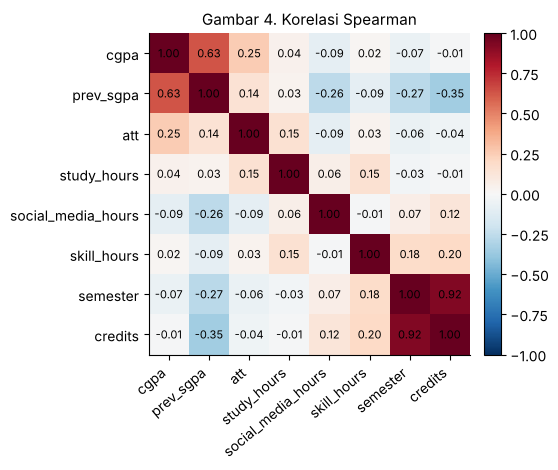

,fitur,n,spearman,p_value
0,prev_sgpa,1155,0.626,0.000
1,att,1154,0.251,0.000
2,social_media_hours,1155,-0.088,0.003
3,semester,1155,-0.067,0.023
4,study_hours,1155,0.042,0.150
5,consultancy_bin,1155,-0.036,0.218
6,study_sessions,1155,0.032,0.282
7,skill_hours,1155,0.020,0.496
8,cocurricular_bin,1155,0.009,0.752


Tebak rata-rata                R2 = -0.003 | MAE = 0.392
Regresi linear, semua fitur    R2 =  0.447 | MAE = 0.268
Regresi linear, tanpa SGPA     R2 =  0.029 | MAE = 0.380


In [10]:
num = ['cgpa','prev_sgpa','att','study_hours','social_media_hours','skill_hours','semester','credits']
corr = d[num].corr(method='spearman')
fig, ax = plt.subplots(figsize=(6.2, 4.8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=40, ha='right')
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)): ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, fraction=0.046, pad=0.03); ax.set_title('Gambar 4. Korelasi Spearman', fontsize=11)
plt.tight_layout(); plt.show()

# korelasi tiap fitur terhadap target
kand = ['prev_sgpa','att','study_hours','study_sessions','social_media_hours','skill_hours','semester','cocurricular_bin','consultancy_bin']
rows = []
for f in kand:
    p2 = d[[f,'cgpa']].dropna(); r, p = stats.spearmanr(p2[f], p2.cgpa); rows.append((f, len(p2), r, p))
korel = pd.DataFrame(rows, columns=['fitur','n','spearman','p_value']).assign(abs_r=lambda x: x.spearman.abs()).sort_values('abs_r', ascending=False).drop(columns='abs_r')
display(korel.round(3).reset_index(drop=True))

# baseline regresi (validasi silang 5-fold) untuk memeriksa peran SGPA
fit_reg = ['prev_sgpa','att','study_hours','study_sessions','social_media_hours','skill_hours','semester']
dd = d.dropna(subset=fit_reg); kf = KFold(5, shuffle=True, random_state=42)
for nama, model, cols_ in [('Tebak rata-rata', DummyRegressor(), fit_reg),
                           ('Regresi linear, semua fitur', LinearRegression(), fit_reg),
                           ('Regresi linear, tanpa SGPA', LinearRegression(), [f for f in fit_reg if f != 'prev_sgpa'])]:
    h = cross_validate(model, dd[cols_].values, dd.cgpa.values, cv=kf, scoring=('r2','neg_mean_absolute_error'))
    print(f"{nama:30s} R2 = {h['test_r2'].mean():6.3f} | MAE = {-h['test_neg_mean_absolute_error'].mean():.3f}")

## Tiga insight yang dipakai untuk keputusan cleaning dan modeling

| # | Temuan (bukti) | Keputusan |
|---|---|---|
| 1 | **CGPA = 0** pada 39 mahasiswa (37 di semester 1, 35 tanpa kredit); menghasilkan 45 outlier CGPA pada data mentah (Bagian 3) | **Cleaning:** 39 baris dikeluarkan. Outlier CGPA turun menjadi 8. |
| 2 | **`prev_sgpa` berkorelasi paling kuat dengan CGPA** (Spearman 0,63); R² regresi 0,45 dengan SGPA vs 0,03 tanpa SGPA | **Modeling:** dibuat **dua skenario** (dengan dan tanpa SGPA) agar kebocoran informasi akademik tidak menutupi peran kegiatan. |
| 3 | **Kehadiran** satu-satunya kegiatan yang berhubungan nyata (Spearman 0,25; p < 0,001); media sosial negatif sangat lemah (−0,09). Ko-kurikuler, konsultasi, jam belajar, dan jam keterampilan hampir nol | **Modeling:** `att` dipertahankan sebagai fitur kegiatan utama; fitur lemah tetap disertakan agar hasil negatifnya dapat dilaporkan, dengan ekspektasi performa model kegiatan saja rendah. |
| 4 | **Distribusi condong** (CGPA kiri; jam belajar/media sosial kanan), sehingga asumsi normalitas tidak terpenuhi | **Analisis:** uji tahan outlier (Spearman, Mann-Whitney) dan imputasi **median**, bukan mean. |

Korelasi bukan sebab-akibat. Hubungan kehadiran–CGPA bisa dua arah, dan hasil hanya berlaku untuk sampel ini.

# 9. Audit kualitas data per kolom

Tabel di bawah menghitung **missing**, **outlier (IQR)**, dan **nilai berulang** untuk setiap kolom data mentah. Kehadiran dikonversi ke angka sementara agar isian `94-98` terdeteksi sebagai gagal konversi, bukan tersembunyi.

In [11]:
KOL_NUM = ['admit_year','age','hsc_year','semester','study_hours','study_sessions','social_media_hours','attendance',
           'skill_hours','prev_sgpa','cgpa','credits','income']

def audit(frame):
    out = []
    for col in NAMA:
        s = frame[col]
        r = dict(kolom=col, tipe=str(s.dtype), missing=int(s.isna().sum()), missing_pct=round(s.isna().mean()*100, 2),
                 unik=int(s.nunique()), nilai_berulang=int(s.dropna().duplicated().sum()),
                 gagal_konversi=np.nan, outlier_iqr=np.nan, batas_bawah=np.nan, batas_atas=np.nan)
        if col in KOL_NUM:
            v = pd.to_numeric(s, errors='coerce'); q1, q3 = v.quantile([.25, .75]); i = q3 - q1
            lo, hi = q1 - 1.5*i, q3 + 1.5*i
            r.update(gagal_konversi=int((s.notna() & v.isna()).sum()), outlier_iqr=int(((v < lo) | (v > hi)).sum()),
                     batas_bawah=round(lo, 2), batas_atas=round(hi, 2))
        out.append(r)
    return pd.DataFrame(out).set_index('kolom')

audit_mentah = audit(mentah)
print('Duplikat baris utuh:', int(mentah[NAMA].duplicated().sum()))
display(audit_mentah)
print('\nKolom dengan missing         :', audit_mentah.index[audit_mentah.missing > 0].tolist())
print('Kolom gagal konversi         :', audit_mentah.index[audit_mentah.gagal_konversi > 0].tolist())
print('5 kolom dengan outlier terbanyak:'); print(audit_mentah.outlier_iqr.dropna().sort_values(ascending=False).head(5).astype(int).to_string())

Duplikat baris utuh: 0


,tipe,missing,missing_pct,unik,nilai_berulang,gagal_konversi,outlier_iqr,batas_bawah,batas_atas
kolom,,,,,,,,,
admit_year,int64,0,0.00,11,1183,0.0,13.0,2017.00,2025.00
gender,str,0,0.00,2,1192,NaN,NaN,NaN,NaN
age,int64,0,0.00,10,1184,0.0,13.0,17.00,25.00
hsc_year,int64,0,0.00,12,1182,0.0,125.0,2017.50,2021.50
program,str,0,0.00,1,1193,NaN,NaN,NaN,NaN
semester,int64,0,0.00,22,1172,0.0,5.0,-7.50,20.50
scholarship,str,0,0.00,2,1192,NaN,NaN,NaN,NaN
uni_transport,str,0,0.00,2,1192,NaN,NaN,NaN,NaN
study_hours,int64,0,0.00,12,1182,0.0,22.0,-1.00,7.00



Kolom dengan missing         : ['skills']
Kolom gagal konversi         : ['attendance']
5 kolom dengan outlier terbanyak:
kolom
hsc_year              125
social_media_hours     71
income                 61
cgpa                   45
study_sessions         42


**Analisis.**
- **Missing:** hanya `skills` (1 baris, 0,08%). Tidak mengganggu analisis.
- **Duplikat:** tidak ada baris utuh yang ganda. Kolom `nilai_berulang` **bukan** tanda kesalahan: kategori Yes/No atau tahun yang sama memang wajar berulang. Tidak ada ID responden, sehingga duplikat observasi hanya bisa diperiksa pada baris utuh.
- **Outlier:** terbanyak pada `hsc_year` (125), tetapi itu karena sebaran sangat sempit (mayoritas 2019–2020) sehingga batas IQR rapat, bukan 125 kesalahan; hanya 1 nilai (2028) yang mustahil. Berikutnya `social_media_hours` (71), `income` (61), `cgpa` (45, hampir semuanya CGPA = 0), `study_sessions` (42), dan `attendance` (36). Yang masuk akal (jam media sosial tinggi, pendapatan tinggi) **dipertahankan**; outlier pada tahun, usia, dan semester hanya penanda pemeriksaan.
- **Gagal konversi:** hanya `attendance` (1 isian `94-98`).

# 10. Cleaning

Strategi per masalah (logika lengkap ada di Bagian 4 notebook utama; di sini kondisi hasilnya **diverifikasi** pada `data/data_bersih.csv`).

In [12]:
strategi = pd.DataFrame([
 ('Label ganda (health_issue, relationship, skills, interest)', 'Standardisasi label', 'Artinya sama; tidak ada responden dibuang'),
 ("Kehadiran '94-98'", 'Dijadikan kosong, imputasi median saat preprocessing', 'Hanya 1 baris; rentang tidak bisa dipastikan nilai tunggalnya'),
 ('Tahun HSC 2028', 'Dijadikan kosong', 'Mustahil (kesalahan input); HSC tidak dipakai sebagai fitur'),
 ('CGPA = 0 (39 baris)', 'Baris dikeluarkan', 'Mahasiswa baru belum punya nilai; menjadi target palsu bila dipertahankan'),
 ('Outlier jam media sosial, pendapatan, dll.', 'Dipertahankan', 'Masih masuk akal; dihadapi dengan uji tahan outlier dan imputasi median'),
], columns=['masalah', 'strategi', 'alasan'])
display(strategi)

# verifikasi hasil cleaning pada data_bersih.csv
cek = {
 'tidak ada CGPA = 0'            : bool((bersih.cgpa > 0).all()),
 'health_issue hanya Yes/No'     : set(bersih.health_issue.unique()) <= {'Yes', 'No'},
 "relationship tanpa 'In a relationship'": 'In a relationship' not in set(bersih.relationship),
 "skills tanpa 'nothing'/'no skills'"    : not set(bersih.skills.unique()) & {'nothing', 'no skills'},
 "interest tanpa salah ketik 'data schince'": 'data schince' not in set(bersih.interest),
 'tidak ada HSC > 2024'          : bool((bersih.hsc_year.dropna() <= 2024).all()),
 'kolom att bertipe angka'       : pd.api.types.is_numeric_dtype(bersih.att),
 'tidak ada baris ganda'         : int(bersih.duplicated().sum()) == 0,
}
for k, v in cek.items(): print(('LULUS  ' if v else 'GAGAL  ') + k)
assert all(cek.values())

,masalah,strategi,alasan
0,"Label ganda (health_issue, relationship, skills, interest)",Standardisasi label,Artinya sama; tidak ada responden dibuang
1,Kehadiran '94-98',"Dijadikan kosong, imputasi median saat preprocessing",Hanya 1 baris; rentang tidak bisa dipastikan nilai tunggalnya
2,Tahun HSC 2028,Dijadikan kosong,Mustahil (kesalahan input); HSC tidak dipakai sebagai fitur
3,CGPA = 0 (39 baris),Baris dikeluarkan,Mahasiswa baru belum punya nilai; menjadi target palsu bila dipertahankan
4,"Outlier jam media sosial, pendapatan, dll.",Dipertahankan,Masih masuk akal; dihadapi dengan uji tahan outlier dan imputasi median


LULUS  tidak ada CGPA = 0
LULUS  health_issue hanya Yes/No
LULUS  relationship tanpa 'In a relationship'
LULUS  skills tanpa 'nothing'/'no skills'
LULUS  interest tanpa salah ketik 'data schince'
LULUS  tidak ada HSC > 2024
LULUS  kolom att bertipe angka
LULUS  tidak ada baris ganda


**Nilai janggal yang masih tersisa** setelah cleaning. Dihitung dan dijelaskan, bukan didiamkan:

In [13]:
sisa = pd.DataFrame([
 ('prev_sgpa = 0', int((bersih.prev_sgpa == 0).sum())),
 ('CGPA < 1',      int((bersih.cgpa < 1).sum())),
 ('Kehadiran = 0', int((bersih.att == 0).sum())),
 ('Kehadiran < 50%', int((bersih.att < 50).sum())),
 ('Semester > 14', int((bersih.semester > 14).sum())),
], columns=['kondisi', 'jumlah_baris'])
display(sisa)
print('Semester maksimum:', bersih.semester.max(), '| CGPA terendah:', bersih.cgpa.nsmallest(3).round(2).tolist())
print('Kehadiran 0%: CGPA =', bersih.loc[bersih.att == 0, 'cgpa'].round(2).tolist())

,kondisi,jumlah_baris
0,prev_sgpa = 0,2
1,CGPA < 1,2
2,Kehadiran = 0,1
3,Kehadiran < 50%,36
4,Semester > 14,15


Semester maksimum: 24 | CGPA terendah: [0.13, 0.5, 1.42]
Kehadiran 0%: CGPA = [3.15]


**Keputusan untuk nilai janggal tersisa: dipertahankan dan ditandai sebagai keterbatasan, tidak dihapus.**
- Jumlahnya sangat kecil (1–2 baris untuk `prev_sgpa = 0`, CGPA < 1, dan kehadiran 0%; 15 baris untuk semester > 14) dibanding 1.155 baris, sehingga pengaruhnya pada korelasi berbasis peringkat (Spearman) kecil.
- Tidak ada bukti pasti bahwa nilai tersebut salah: semester tinggi dapat berarti mahasiswa lama, dan CGPA rendah dapat nyata. Menghapus tanpa bukti justru menimbulkan bias.
- Satu kasus tampak janggal (kehadiran 0% tetapi CGPA 3,15), kemungkinan salah input. Dampaknya diredam karena analisis memakai Spearman yang berbasis peringkat, dan kasus ini dicatat sebagai keterbatasan. Ada juga 36 baris dengan kehadiran < 50% yang sebagian mungkin nyata dan tetap dipertahankan.
- Konsekuensinya: angka di laporan tetap konsisten dengan notebook utama.

# 11. Kondisi sebelum vs sesudah cleaning

In [14]:
def ringkas(frame, att_col):
    return {
     'Jumlah baris'              : len(frame),
     'Baris duplikat utuh'       : int(frame[NAMA].duplicated().sum()),
     'Sel kosong / tak terbaca': int(frame[NAMA].isna().sum().sum()) + int(frame[att_col].isna().sum()),
     'Baris CGPA = 0'            : int((frame.cgpa == 0).sum()),
     'Tahun HSC > 2024'          : int((frame.hsc_year > 2024).sum()),
     'Label health_issue unik'   : frame.health_issue.nunique(),
     'Label skills unik'         : frame.skills.nunique(),
     'Rata-rata CGPA'            : round(frame.cgpa.mean(), 3),
     'Skewness CGPA'             : round(frame.cgpa.skew(), 2),
     'Outlier IQR: cgpa'         : iqr_outlier(frame.cgpa),
     'Outlier IQR: kehadiran'    : iqr_outlier(frame[att_col]),
     'Outlier IQR: media sosial' : iqr_outlier(frame.social_media_hours),
     'Outlier IQR: income'       : iqr_outlier(frame.income),
    }
bandingan = pd.DataFrame({'sebelum (mentah)': ringkas(mentah, 'att'), 'sesudah (bersih)': ringkas(bersih, 'att')})
display(bandingan.map(lambda v: f'{v:g}'))

,sebelum (mentah),sesudah (bersih)
Jumlah baris,1194,1155
Baris duplikat utuh,0,0
Sel kosong / tak terbaca,2,2
Baris CGPA = 0,39,0
Tahun HSC > 2024,1,0
Label health_issue unik,4,2
Label skills unik,55,42
Rata-rata CGPA,3.166,3.272
Skewness CGPA,-2.5,-0.84
Outlier IQR: cgpa,45,8


**Interpretasi.**
- Baris turun dari 1.194 menjadi **1.155** (39 mahasiswa dengan CGPA = 0). Rata-rata CGPA naik dari 3,17 menjadi 3,27 dan skewness membaik dari −2,50 menjadi −0,84, karena distribusi tidak lagi dibelokkan oleh nilai 0.
- Outlier CGPA turun dari 45 menjadi 8, hampir seluruhnya karena nilai 0 hilang.
- Label `health_issue` menjadi 2 kategori (Yes/No) dan label `skills` berkurang dari 55 menjadi 42 karena penulisan sama disatukan.
- Jumlah sel kosong tampak sama (2 → 2) tetapi isinya berbeda: sebelumnya `skills` dan kehadiran `94-98`; sesudahnya tahun HSC 2028 dan kehadiran `94-98` (label `skills` kosong sudah diisi `Unknown`).
- Outlier variabel lain nyaris tidak berubah karena sengaja dipertahankan. Batas IQR dihitung ulang pada tiap tahap, jadi perubahan jumlah outlier juga dipengaruhi perubahan distribusi.
- Populasi analisis berubah: kesimpulan hanya berlaku untuk mahasiswa yang sudah punya CGPA.

# 12. Preprocessing: encoding, scaling, imbalance

In [15]:
# Encoding: indikator Yes/No -> 1/0 (sudah ada di data_bersih.csv); pastikan sesuai dengan label aslinya
for col in ['cocurricular', 'consultancy']:
    assert bersih[col].isin(['Yes', 'No']).all()
    assert (bersih[col + '_bin'] == (bersih[col] == 'Yes').astype(int)).all()
print('Encoding Yes/No -> 1/0 sesuai label asli (cocurricular_bin, consultancy_bin).')

fitur_angka  = ['att', 'study_hours', 'study_sessions', 'social_media_hours', 'skill_hours', 'semester']
fitur_biner  = ['cocurricular_bin', 'consultancy_bin']
X = bersih[['prev_sgpa'] + fitur_angka + fitur_biner]; y = bersih.cgpa

# Pembagian dulu (Bagian 13), baru imputasi + scaling dilatih HANYA pada data latih
X_latih, X_uji, y_latih, y_uji = train_test_split(X, y, test_size=0.2, random_state=42)

def pipeline_pra(kol_angka, kol_biner):
    return ColumnTransformer([
        ('angka', Pipeline([('isi', SimpleImputer(strategy='median')), ('skala', StandardScaler())]), kol_angka),
        ('biner', 'passthrough', kol_biner)])

skenario = {'dengan_sgpa': (['prev_sgpa'] + fitur_angka, fitur_biner), 'tanpa_sgpa': (fitur_angka, fitur_biner)}
hasil = {}
for nama, (ang, bn) in skenario.items():
    pre = pipeline_pra(ang, bn).fit(X_latih[ang + bn])
    a, b = pre.transform(X_latih[ang + bn]), pre.transform(X_uji[ang + bn]); hasil[nama] = (a, b)
    print(f'{nama:12s} latih {a.shape} | uji {b.shape} | rata-rata fitur angka (latih) {a[:, :len(ang)].mean():.3f}'
          f' | std {a[:, :len(ang)].std():.3f} | nilai kosong {int(np.isnan(a).sum() + np.isnan(b).sum())}')

Encoding Yes/No -> 1/0 sesuai label asli (cocurricular_bin, consultancy_bin).


dengan_sgpa  latih (924, 9) | uji (231, 9) | rata-rata fitur angka (latih) 0.000 | std 1.000 | nilai kosong 0
tanpa_sgpa   latih (924, 8) | uji (231, 8) | rata-rata fitur angka (latih) 0.000 | std 1.000 | nilai kosong 0


In [16]:
# Distribusi target (data latih) untuk pemeriksaan imbalance
bin_t = pd.cut(y_latih, bins=[-np.inf, 2, 2.5, 3, 3.5, np.inf], labels=['<2','2-<2.5','2.5-<3','3-<3.5','>=3.5'], right=False)
imb = bin_t.value_counts(sort=False)
display(pd.DataFrame({'jumlah_latih': imb, 'persen_latih': (100*imb/len(y_latih)).round(2)}))

,jumlah_latih,persen_latih
cgpa,,
<2,9,0.97
2-<2.5,38,4.11
2.5-<3,204,22.08
3-<3.5,326,35.28
>=3.5,347,37.55


| Langkah | Metode | Alasan |
|---|---|---|
| **Encoding** | Indikator 0/1 untuk `cocurricular` dan `consultancy` | Hanya dua kategori (Yes/No); 0/1 mempertahankan makna tanpa menciptakan urutan palsu. Kolom kategorikal lain (mis. `skills`, `interest`) belum dipakai karena labelnya beragam dan butuh penyederhanaan tersendiri (Bagian 14). |
| **Imputasi** | Median, dilatih hanya pada data latih | Ada nilai kosong (kehadiran) dan data condong/ekstrem; median lebih tahan terhadap nilai ekstrem daripada mean. |
| **Scaling** | `StandardScaler` pada fitur angka, dilatih hanya pada data latih | Menyamakan skala (persen kehadiran vs jam/hari) untuk perbandingan dan model berikutnya. Tidak menghapus outlier. Fitur biner tetap 0/1. |
| **Imbalance** | **Tidak ada resampling (SMOTE dkk. tidak dipakai)** | Target adalah CGPA kontinu, bukan kelas, sehingga konsep kelas minoritas tidak berlaku. Distribusi target tetap diperiksa: ±73% data berada di rentang CGPA 3,0 ke atas, hanya ±1% di bawah 2,0. Menggandakan data di ekor yang kecil dapat merusak distribusi survei. Pada pemodelan lanjutan, laporkan MAE per rentang CGPA di samping MAE/R² keseluruhan. |

Imbalance di sini berarti **ekor target yang tipis**, dan ini dicatat sebagai risiko: model dapat kurang akurat untuk CGPA sangat rendah.

# 13. Split train/test

In [17]:
print(f'Data latih: {X_latih.shape[0]} baris ({X_latih.shape[0]/len(X):.0%}) | data uji: {X_uji.shape[0]} baris ({X_uji.shape[0]/len(X):.0%})')
print(f'Rata-rata CGPA latih {y_latih.mean():.3f} vs uji {y_uji.mean():.3f} | SD latih {y_latih.std():.3f} vs uji {y_uji.std():.3f}')
assert len(X_latih) + len(X_uji) == len(bersih) and not set(X_latih.index) & set(X_uji.index)
print('Tidak ada baris yang muncul di latih dan uji sekaligus.')

Data latih: 924 baris (80%) | data uji: 231 baris (20%)
Rata-rata CGPA latih 3.267 vs uji 3.293 | SD latih 0.491 vs uji 0.441
Tidak ada baris yang muncul di latih dan uji sekaligus.


**Pembagian 80:20 dengan `random_state=42`** (hasil reprodusibel). Pembagian dilakukan **sebelum** imputasi dan scaling, sehingga statistik median/rata-rata/SD hanya dipelajari dari data latih dan tidak ada kebocoran dari data uji. Stratifikasi tidak dipakai karena target kontinu; rata-rata CGPA kedua bagian mirip (3,27 vs 3,29) dan SD cukup dekat (0,49 vs 0,44), tanda pembagian cukup representatif.

# 14. Seleksi fitur

Bukti: korelasi Spearman tiap fitur kandidat dengan CGPA (Bagian 8). Keputusan mengikuti **pertanyaan proyek** (kegiatan internal/eksternal) dan risiko kebocoran, bukan sekadar nilai p.

In [18]:
rho = korel.set_index('fitur')
def bukti(f): return f"rho = {rho.loc[f,'spearman']:+.2f}; p = {rho.loc[f,'p_value']:.3f}"
keputusan = pd.DataFrame([
 ('prev_sgpa',          'Dipakai (skenario dengan SGPA saja)', 'Korelasi paling kuat; bukan kegiatan, jadi dikeluarkan pada skenario tanpa SGPA agar peran kegiatan terlihat', bukti('prev_sgpa')),
 ('att',                'Dipakai', 'Kegiatan internal; satu-satunya yang berhubungan nyata', bukti('att')),
 ('social_media_hours', 'Dipakai', 'Kegiatan eksternal; hubungan negatif sangat lemah tetapi nyata', bukti('social_media_hours')),
 ('semester',           'Dipakai (kontrol)', 'Mengontrol tahap studi', bukti('semester')),
 ('study_hours',        'Dipakai', 'Kegiatan eksternal; hasil nol dilaporkan, tidak dibuang', bukti('study_hours')),
 ('study_sessions',     'Dipakai', 'Kegiatan eksternal; melengkapi jam belajar', bukti('study_sessions')),
 ('skill_hours',        'Dipakai', 'Kegiatan eksternal; hasil nol dilaporkan', bukti('skill_hours')),
 ('consultancy_bin',    'Dipakai', 'Kegiatan internal; arah hubungan bisa terbalik (yang kesulitan lebih sering konsultasi)', bukti('consultancy_bin')),
 ('cocurricular_bin',   'Dipakai', 'Kegiatan internal; hasil nol dilaporkan', bukti('cocurricular_bin')),
 ('cgpa',               'Target, bukan fitur', 'Variabel yang diprediksi', '-'),
 ('credits, probation, suspension', 'Dibuang', 'Terlalu dekat dengan hasil/progres akademik; berisiko membuat evaluasi tidak adil bila diketahui setelah CGPA', '-'),
 ('gender, age, admit_year, program, income', 'Dibuang', 'Tidak menjawab fokus pengaruh kegiatan; program hanya satu nilai (BCSE); mata uang income belum terverifikasi', '-'),
 ('skills, interest',   'Dibuang (sementara)', 'Label teks sangat beragam; perlu penyederhanaan kategori sendiri dan kegunaannya terhadap CGPA tidak signifikan (Kruskal-Wallis keterampilan p = 0,50)', '-'),
], columns=['fitur', 'keputusan', 'alasan', 'bukti'])
display(keputusan)
grup = [x.cgpa.values for _, x in bersih.groupby('skills') if len(x) >= 20]
print(f'Kruskal-Wallis jenis keterampilan: {len(grup)} kelompok (n >= 20), p = {stats.kruskal(*grup).pvalue:.2f}')

,fitur,keputusan,alasan,bukti
0,prev_sgpa,Dipakai (skenario dengan SGPA saja),"Korelasi paling kuat; bukan kegiatan, jadi dikeluarkan pada skenario tanpa S...",rho = +0.63; p = 0.000
1,att,Dipakai,Kegiatan internal; satu-satunya yang berhubungan nyata,rho = +0.25; p = 0.000
2,social_media_hours,Dipakai,Kegiatan eksternal; hubungan negatif sangat lemah tetapi nyata,rho = -0.09; p = 0.003
3,semester,Dipakai (kontrol),Mengontrol tahap studi,rho = -0.07; p = 0.023
4,study_hours,Dipakai,"Kegiatan eksternal; hasil nol dilaporkan, tidak dibuang",rho = +0.04; p = 0.150
5,study_sessions,Dipakai,Kegiatan eksternal; melengkapi jam belajar,rho = +0.03; p = 0.282
6,skill_hours,Dipakai,Kegiatan eksternal; hasil nol dilaporkan,rho = +0.02; p = 0.496
7,consultancy_bin,Dipakai,Kegiatan internal; arah hubungan bisa terbalik (yang kesulitan lebih sering ...,rho = -0.04; p = 0.218
8,cocurricular_bin,Dipakai,Kegiatan internal; hasil nol dilaporkan,rho = +0.01; p = 0.752
9,cgpa,"Target, bukan fitur",Variabel yang diprediksi,-


Kruskal-Wallis jenis keterampilan: 7 kelompok (n >= 20), p = 0.50


**Catatan.**
- **Tidak ada fitur baru yang dibuat.** `cocurricular_bin` dan `consultancy_bin` adalah *encoding* Yes/No → 1/0, bukan feature engineering.
- Fitur lemah **sengaja dipertahankan**: hasil bahwa ko-kurikuler dan konsultasi tidak berpengaruh adalah temuan yang perlu dilaporkan.
- Fitur yang dibuang bukan berarti tidak berguna secara umum, hanya di luar ruang lingkup model ini.

---
# Ringkasan capaian

| No | Item | Bukti di notebook ini | Status |
|---|---|---|---|
| 1 | Sumber data & lisensi | Bagian 1 | ✅ |
| 2 | Data dictionary | Bagian 2 (31 variabel, terverifikasi terhadap data) | ✅ |
| 3 | Kualitas data | Bagian 3 | ✅ |
| 4 | EDA berinsight | Bagian 4 | ✅ |
| 5 | Representativitas & bias | Bagian 5 | ✅ |
| 6 | Statistik deskriptif | Bagian 6 | ✅ |
| 7 | Visualisasi fitur dan target | Bagian 7 (Gambar 1–3) | ✅ |
| 8 | Korelasi + ≥3 insight | Bagian 8 (tabel 4 insight → keputusan) | ✅ |
| 9 | Audit per kolom | Bagian 9 | ✅ |
| 10 | Cleaning | Bagian 10 (strategi, verifikasi, nilai janggal tersisa) | ✅ |
| 11 | Sebelum vs sesudah | Bagian 11 | ✅ |
| 12 | Encoding, scaling, imbalance | Bagian 12 (dengan alasan) | ✅ |
| 13 | Split train/test | Bagian 13 | ✅ |
| 14 | Feature selection | Bagian 14 (bukti + alasan) | ✅ |

**Keterbatasan:** hasil hanya menunjukkan hubungan, bukan sebab-akibat; data satu program di satu kampus, survei self-report; mata uang `income` dan batas skala resmi SGPA/CGPA belum terverifikasi dari sumber; sebagian kecil nilai janggal dipertahankan dan ditandai.